In [11]:
import seaborn as sns
import matplotlib.pyplot as plt

import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.font_manager import FontProperties, fontManager
from matplotlib.ticker import FuncFormatter
import matplotlib.colors as mcolors

sns.set_theme(style="ticks", rc={"axes.facecolor": (0, 0, 0, 0)}, font_scale=1.2)
font_path = '../Helvetica.ttf' 
fontManager.addfont(font_path)
prop = FontProperties(fname=font_path)
font_name = prop.get_name()
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = [font_name] 
print("Current font settings:", plt.rcParams['font.sans-serif'])


Current font settings: ['Helvetica']


## Download evaluation results

In [20]:
import pandas as pd

res = pd.read_csv('../UniPert/results/chemical_perturbation_sciplex_all_results.csv', index_col=0)
res

,model,dataset,split_key,cell_type,condition,dose,n_top_deg,r2_mean_deg,mse_mean_deg,pcc_mean_deg,ccc_mean_deg
0,chemCPA,sciplex3_all,ood_split_2,A549,Selisistat,0.001,10,0.749042,0.002466,0.991762,0.915895
1,chemCPA_noPerturb,sciplex3_all,ood_split_2,A549,Selisistat,0.001,10,0.725320,0.002699,0.974569,0.904773
2,chemCPA,sciplex3_all,ood_split_2,A549,Selisistat,0.001,20,0.908536,0.001332,0.987121,0.962545
3,chemCPA_noPerturb,sciplex3_all,ood_split_2,A549,Selisistat,0.001,20,0.841483,0.002308,0.989840,0.941554
4,chemCPA,sciplex3_all,ood_split_2,A549,Selisistat,0.001,50,0.980010,0.001101,0.995455,0.990676
...,...,...,...,...,...,...,...,...,...,...,...
2879995,UniPert_noPerturb,sciplex3_all,ood_split_1,K562,Flavopiridol,1.000,20,0.912200,0.189552,0.968750,0.947839
2879996,UniPert,sciplex3_all,ood_split_1,K562,Flavopiridol,1.000,50,0.952315,0.064276,0.985084,0.972558
2879997,UniPert_noPerturb,sciplex3_all,ood_split_1,K562,Flavopiridol,1.000,50,0.917525,0.111171,0.969344,0.951037
2879998,UniPert,sciplex3_all,ood_split_1,K562,Flavopiridol,1.000,all,0.424285,0.013600,0.690414,0.683149


In [7]:
res['model'].value_counts()


model
chemCPA              720000
chemCPA_noPerturb    720000
UniPert              720000
UniPert_noPerturb    720000
Name: count, dtype: int64

In [8]:
res['split_key'].value_counts()


split_key
ood_split_2    576000
ood_split_5    576000
ood_split_4    576000
ood_split_3    576000
ood_split_1    576000
Name: count, dtype: int64

In [11]:
res.groupby(['model'])[['r2_mean_deg', 'pcc_mean_deg', 'ccc_mean_deg', 'mse_mean_deg']].mean()

,r2_mean_deg,pcc_mean_deg,ccc_mean_deg,mse_mean_deg
model,,,,
UniPert,-0.054358,0.948144,0.911915,0.029820
UniPert_noPerturb,-0.954829,0.932668,0.896956,0.034349
chemCPA,-0.110351,0.945713,0.908718,0.032896
chemCPA_noPerturb,-0.954829,0.932668,0.896956,0.034349


In [12]:
res[(res['model'].isin(['UniPert', 'chemCPA', 'chemCPA_noPerturb']))].groupby(
    ['n_top_deg', 'cell_type', 'model'])[['r2_mean_deg', 'pcc_mean_deg', 'ccc_mean_deg', 'mse_mean_deg']].mean()

r2_mean_deg  pcc_mean_deg  \
n_top_deg cell_type model                                          
10        A549      UniPert              -0.897401      0.940743   
                    chemCPA              -0.959198      0.940765   
                    chemCPA_noPerturb    -3.195960      0.919207   
          K562      UniPert              -5.730087      0.868957   
                    chemCPA              -6.062603      0.869981   
                    chemCPA_noPerturb   -11.223519      0.822025   
          MCF7      UniPert               0.600252      0.947113   
                    chemCPA               0.628452      0.940872   
                    chemCPA_noPerturb     0.372321      0.932090   
20        A549      UniPert               0.595204      0.954120   
                    chemCPA               0.568151      0.951372   
                    chemCPA_noPerturb     0.214328      0.937105   
          K562      UniPert              -1.499717      0.904728   
                    chemCPA              -1.745152      0.901441   
                    chemCPA_noPerturb    -3.748706      0.875526   
          MCF7      UniPert               0.867864      0.961383   
                    chemCPA               0.861952      0.955515   
                    chemCPA_noPerturb     0.845883      0.951316   
50        A549      UniPert               0.898434      0.960823   
                    chemCPA               0.893505      0.957412   
                    chemCPA_noPerturb     0.869359      0.950981   
          K562      UniPert               0.735745      0.931999   
                    chemCPA               0.714766      0.928186   
                    chemCPA_noPerturb     0.669398      0.916030   
          MCF7      UniPert               0.904830      0.965587   
                    chemCPA               0.899326      0.961050   
                    chemCPA_noPerturb     0.890555      0.958257   
all       A549      UniPert               0.959668      0.980677   
                    chemCPA               0.959634      0.980511   
                    chemCPA_noPerturb     0.951394      0.976301   
          K562      UniPert               0.942266      0.972820   
                    chemCPA               0.944362      0.972897   
                    chemCPA_noPerturb     0.926773      0.964770   
          MCF7      UniPert               0.970648      0.986231   
                    chemCPA               0.972592      0.986118   
                    chemCPA_noPerturb     0.970226      0.984840   

                                       ccc_mean_deg  mse_mean_deg  
n_top_deg cell_type model                                          
10        A549      UniPert                0.878453      0.061985  
                    chemCPA                0.874355      0.069148  
                    chemCPA_noPerturb      0.856485      0.071183  
          K562      UniPert                0.700159      0.032485  
                    chemCPA                0.696670      0.036202  
                    chemCPA_noPerturb      0.661553      0.036256  
          MCF7      UniPert                0.916568      0.071457  
                    chemCPA                0.911950      0.079904  
                    chemCPA_noPerturb      0.904046      0.085042  
20        A549      UniPert                0.919132      0.045201  
                    chemCPA                0.913495      0.049961  
                    chemCPA_noPerturb      0.900364      0.051958  
          K562      UniPert                0.831099      0.024408  
                    chemCPA                0.825634      0.027237  
                    chemCPA_noPerturb      0.798668      0.027748  
          MCF7      UniPert                0.945843      0.050611  
                    chemCPA                0.941750      0.054629  
                    chemCPA_noPerturb      0.936941      0.057802  
50        A549      UniPert                0.948882      0.027553  
                    chemCP

## Plot

### by cell type 

/tmp/ipykernel_3810266/4139958897.py:44: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(ax.get_xticklabels(), fontsize=12)


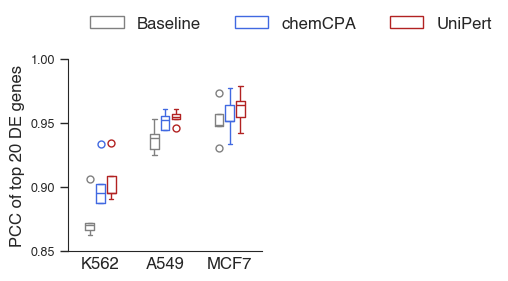

In [ ]:
plt.figure(figsize=(2.5, 2.5))

palatte = ['gray', 'royalblue', 'firebrick']

ax = sns.boxplot(
    data=res[(res['model'].isin(['UniPert', 'chemCPA', 'chemCPA_noPerturb'])) & (res['n_top_deg']=='20')]
        .groupby(['cell_type', 'model', 'split_key'])[['r2_mean_deg', 'pcc_mean_deg', 'ccc_mean_deg', 'mse_mean_deg']]
        .mean()
        .rename(index={
                'chemCPA_noPerturb': 'Baseline',
                'chemCPA': 'chemCPA',
                'UniPert': 'UniPert'
            })
        .sort_values(by='pcc_mean_deg', ascending=True), 
    x="cell_type", 
    y="pcc_mean_deg", 
    hue="model",
    palette=palatte,
    legend=True,
    gap=0.2,
    width=0.5,
    linewidth=1,
    flierprops={'marker': 'o', 'markersize': 5, 'markerfacecolor': 'none'},
    fill=False,
)

ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['left'].set_linewidth(0.8)
ax.spines['bottom'].set_linewidth(0.8)

ax.tick_params(axis='x', which='both', length=0)
ax.tick_params(width=1)

ax.set_ylim(0.85, 1.0)
ax.set_yticks([0.85, 0.9, 0.95, 1.0])
ax.set_yticklabels(ax.get_yticklabels(), fontsize=9)
ax.set_ylabel('PCC of top 20 DE genes', fontsize=12)

ax.set_xticklabels(ax.get_xticklabels(), fontsize=12)
ax.set_xlabel('', fontsize=12)

plt.legend(bbox_to_anchor=(1.15, 1.3), fontsize=12, title_fontsize=12, facecolor='white', ncol=3, loc='upper center', frameon=False)

plt.show()

/tmp/ipykernel_3810266/1241828240.py:39: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(ax.get_yticklabels(), fontsize=9)
/tmp/ipykernel_3810266/1241828240.py:42: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(ax.get_xticklabels(), fontsize=12)


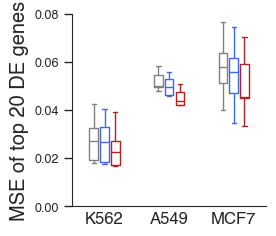

In [16]:
plt.figure(figsize=(2.5, 2.5))

ax = sns.boxplot(
    data=res[(res['model'].isin(['UniPert', 'chemCPA', 'chemCPA_noPerturb'])) & (res['n_top_deg']=='20')]
        .groupby(['cell_type', 'model', 'split_key'])[['r2_mean_deg', 'pcc_mean_deg', 'ccc_mean_deg', 'mse_mean_deg']]
        .mean()
        .rename(index={
                'chemCPA_noPerturb': 'No Perturb',
                'chemCPA': 'chemCPA',
                'UniPert': 'UniPert'
            })
        .sort_values(by='pcc_mean_deg', ascending=True), 
    x="cell_type", 
    y="mse_mean_deg", 
    hue="model",
    #自定义颜色
    palette=palatte,
    legend=False,
    # 箱线宽度
    gap=0.2,
    width=0.5,
    linewidth=1,
    # 箱线颜色
    flierprops={'marker': 'o', 'markersize': 5, 'markerfacecolor': 'none'},
    fill=False,
)

## 去掉右边和上面边框
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['left'].set_linewidth(0.8)
ax.spines['bottom'].set_linewidth(0.8)

ax.tick_params(axis='x', which='both', length=0)
ax.tick_params(width=1)

ax.set_ylim(0.0, 0.08)
# ax.set_yticks([0.85, 0.9, 0.95, 1.0])
ax.set_yticklabels(ax.get_yticklabels(), fontsize=9)
ax.set_ylabel('MSE of top 20 DE genes')

ax.set_xticklabels(ax.get_xticklabels(), fontsize=12)
ax.set_xlabel('', fontsize=12)

plt.show()


### by topDEG for each cell type

/tmp/ipykernel_3810266/1954030994.py:38: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(ax.get_yticklabels(), fontsize=10)
/tmp/ipykernel_3810266/1954030994.py:39: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(ax.get_xticklabels(), fontsize=10)


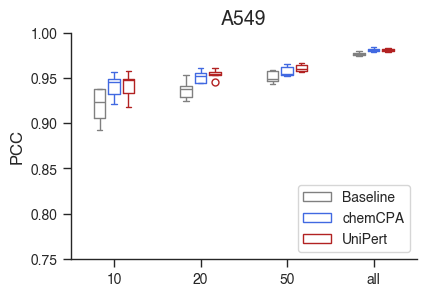

/tmp/ipykernel_3810266/1954030994.py:38: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(ax.get_yticklabels(), fontsize=10)
/tmp/ipykernel_3810266/1954030994.py:39: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(ax.get_xticklabels(), fontsize=10)


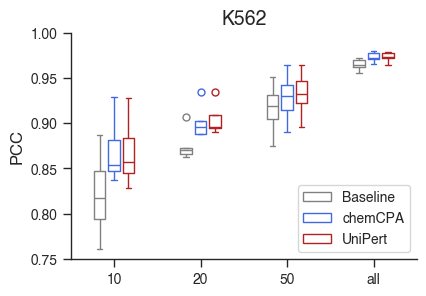

/tmp/ipykernel_3810266/1954030994.py:38: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(ax.get_yticklabels(), fontsize=10)
/tmp/ipykernel_3810266/1954030994.py:39: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(ax.get_xticklabels(), fontsize=10)


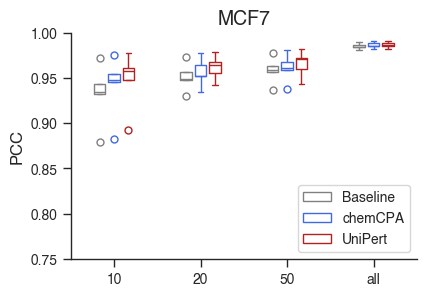

In [30]:
model_order = ['Baseline', 'chemCPA', 'UniPert']
def model_sort_key(index):
    return model_order.index(index)


for cell_type in ['A549', 'K562', 'MCF7']:
    plt.figure(figsize=(4.5, 3.2))

    data = res[(res['model'].isin(['UniPert', 'chemCPA', 'chemCPA_noPerturb'])) & (res['cell_type']==cell_type)]
    data = data.groupby(['n_top_deg', 'model', 'split_key'])[['r2_mean_deg', 'pcc_mean_deg', 'ccc_mean_deg', 'mse_mean_deg']].mean().reset_index()
    data['model'] = data['model'].replace({'chemCPA_noPerturb': 'Baseline'})
    model_order = ['Baseline', 'chemCPA', 'UniPert']
    model_rank = {m: i for i, m in enumerate(model_order)}
    data = data.sort_values(
        by=['n_top_deg', 'model'],
        key=lambda x: x.map(model_rank) if x.name == 'model' else x
    )

    ax = sns.boxplot(
        data=data,
        x="n_top_deg", 
        y="pcc_mean_deg", 
        hue="model",
        gap=0.2,
        width=0.5,
        linewidth=1,
        flierprops={'marker': 'o', 'markersize': 5, 'markerfacecolor': 'none'},
        fill=False,
        palette=palatte,
    )

    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.spines['left'].set_linewidth(1)
    ax.spines['bottom'].set_linewidth(1)

    ax.set_ylim(0.75, 1.0)
    ax.set_yticklabels(ax.get_yticklabels(), fontsize=10)
    ax.set_xticklabels(ax.get_xticklabels(), fontsize=10)
    ax.set_xlabel('', fontsize=12)
    ax.tick_params(width=1)
    ax.set_ylabel('PCC', fontsize=12)
    ax.set_title(cell_type, fontsize=14)
    plt.legend(title='', fontsize=10, title_fontsize=10, facecolor='white', loc='lower right')

    plt.tight_layout()
    plt.show()

/tmp/ipykernel_3810266/2463044539.py:35: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(ax.get_xticklabels(), fontsize=10)


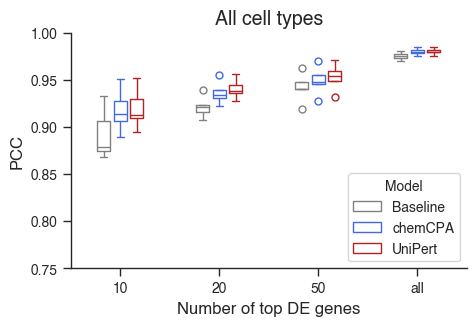

In [31]:
data = res[(res['model'].isin(['UniPert', 'chemCPA', 'chemCPA_noPerturb']))]\
    .groupby(['n_top_deg', 'model', 'split_key'])[['r2_mean_deg', 'pcc_mean_deg', 'ccc_mean_deg', 'mse_mean_deg']]\
    .mean()\
    .rename(index={
                'chemCPA_noPerturb': 'Baseline',
                'chemCPA': 'chemCPA',
                'UniPert': 'UniPert'
            })\
    .sort_values(by='pcc_mean_deg', ascending=True)

plt.figure(figsize=(5, 3.5))

ax = sns.boxplot(
    data=data,
    x="n_top_deg", 
    y="pcc_mean_deg", 
    hue="model",
    gap=0.2,
    width=0.5,
    linewidth=1,
    flierprops={'marker': 'o', 'markersize': 5, 'markerfacecolor': 'none'},
    fill=False,
    palette=palatte,
)


ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['left'].set_linewidth(1)
ax.spines['bottom'].set_linewidth(1)

ax.set_ylim(0.75, 1.0)
ax.set_yticks([0.75, 0.8, 0.85, 0.9, 0.95, 1.0])
ax.set_yticklabels(ax.get_yticklabels(), fontsize=10)
ax.set_xticklabels(ax.get_xticklabels(), fontsize=10)
ax.set_xlabel('Number of top DE genes', fontsize=12)
ax.tick_params(width=1)
ax.set_ylabel('PCC', fontsize=12)
ax.set_title('All cell types', fontsize=14)
plt.legend(title='Model', fontsize=10, title_fontsize=10, facecolor='white', loc='lower right')

plt.tight_layout()

plt.show()

/tmp/ipykernel_3810266/1646811226.py:41: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(ax.get_xticklabels(), fontsize=10)


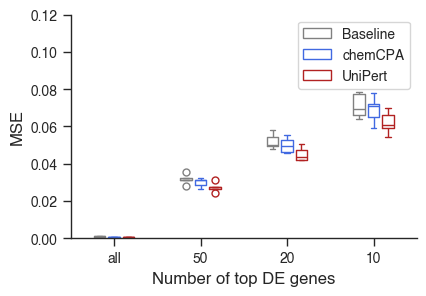

/tmp/ipykernel_3810266/1646811226.py:41: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(ax.get_xticklabels(), fontsize=10)


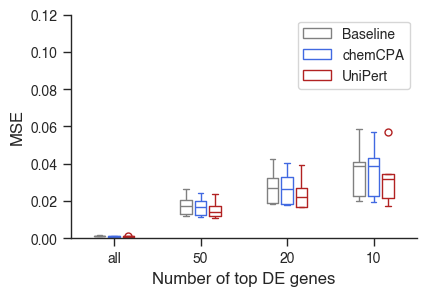

/tmp/ipykernel_3810266/1646811226.py:41: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(ax.get_xticklabels(), fontsize=10)


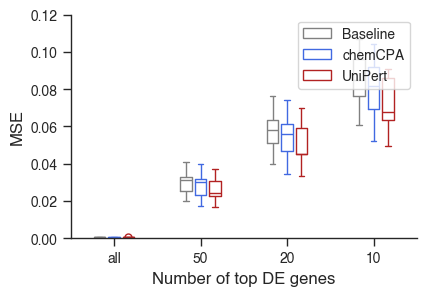

In [33]:

# Define the desired order of models
model_order = ['Baseline', 'chemCPA', 'UniPert']

# Create a custom sorting key function
def model_sort_key(index):
    return model_order.index(index)


for cell_type in ['A549', 'K562', 'MCF7']:
    plt.figure(figsize=(4.5, 3.2))

    data = res[(res['model'].isin(['UniPert', 'chemCPA', 'chemCPA_noPerturb'])) & (res['cell_type']==cell_type)]
    data = data.groupby(['n_top_deg', 'model', 'split_key'])[['r2_mean_deg', 'pcc_mean_deg', 'ccc_mean_deg', 'mse_mean_deg']].mean().reset_index()
    data['model'] = data['model'].replace({'chemCPA_noPerturb': 'Baseline'})
    data = data.sort_values('n_top_deg')
    data = data.sort_values('model', key=lambda x: x.map({m: i for i, m in enumerate(model_order)}))
    

    ax = sns.boxplot(
        data=data,
        x="n_top_deg", 
        y="mse_mean_deg", 
        hue="model",
        gap=0.2,
        width=0.5,
        linewidth=1,
        flierprops={'marker': 'o', 'markersize': 5, 'markerfacecolor': 'none'},
        fill=False,
        palette=palatte,
    )

    ## 去掉右边和上面边框
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.spines['left'].set_linewidth(1)
    ax.spines['bottom'].set_linewidth(1)

    ax.set_ylim(0.0, 0.12)
    ax.set_yticks([0.0, 0.02, 0.04, 0.06, 0.08, 0.1, 0.12])
    ax.set_yticklabels(ax.get_yticklabels(), fontsize=10)
    ax.set_xticklabels(ax.get_xticklabels(), fontsize=10)
    ax.set_xlabel('Number of top DE genes', fontsize=12)
    ax.tick_params(width=1)
    ax.set_ylabel('MSE', fontsize=12)
    ax.set_title('', fontsize=14)
    plt.legend(title='', fontsize=10, title_fontsize=10, facecolor='white', loc='upper right')
    
    plt.tight_layout()
    plt.show()

/tmp/ipykernel_3810266/786898799.py:36: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(ax.get_xticklabels(), fontsize=10)


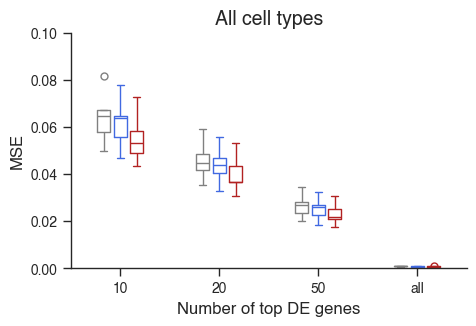

In [ ]:
data = res[(res['model'].isin(['UniPert', 'chemCPA', 'chemCPA_noPerturb']))]\
    .groupby(['n_top_deg', 'model', 'split_key'])[['r2_mean_deg', 'pcc_mean_deg', 'ccc_mean_deg', 'mse_mean_deg']]\
    .mean()\
    .rename(index={
                'chemCPA_noPerturb': 'Baseline',
                'chemCPA': 'chemCPA',
                'UniPert': 'UniPert'
            })\
    .sort_values(by='mse_mean_deg', ascending=False)

plt.figure(figsize=(5, 3.5))

ax = sns.boxplot(
    data=data,
    x="n_top_deg", 
    y="mse_mean_deg", 
    hue="model",
    gap=0.2,
    width=0.5,
    linewidth=1,
    flierprops={'marker': 'o', 'markersize': 5, 'markerfacecolor': 'none'},
    fill=False,
    palette=palatte,
    legend = False
)


ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['left'].set_linewidth(1)
ax.spines['bottom'].set_linewidth(1)

ax.set_ylim(0.0, 0.1)
ax.set_yticks([0.0, 0.02, 0.04, 0.06, 0.08, 0.1])
ax.set_yticklabels(ax.get_yticklabels(), fontsize=10)
ax.set_xticklabels(ax.get_xticklabels(), fontsize=10)
ax.set_xlabel('Number of top DE genes', fontsize=12)
ax.tick_params(width=1)
ax.set_ylabel('MSE', fontsize=12)
ax.set_title('All cell types', fontsize=14)

plt.tight_layout()
plt.show()